<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/apartements_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('Apartments Prices Dataset(Target column price).csv')

In [3]:
print(df.shape)

(5578, 11)


In [4]:
print(df.describe)

<bound method NDFrame.describe of                price area_sqm    rooms   bathrooms floor_level  year_built  \
0      2,163,000 EGP   120 m²  2 rooms  3 bathroom           3        2025   
1      3,250,000 EGP   162 m²  3 rooms  2 bathroom           6        2024   
2      2,650,000 EGP   122 m²  3 rooms  1 bathroom           4        2024   
3     12,720,000 EGP   212 m²  4 rooms  3 bathroom          13        2027   
4      5,898,000 EGP   135 m²  2 rooms  1 bathroom           6        2025   
...              ...      ...      ...         ...         ...         ...   
5573  13,200,000 EGP   168 m²  3 rooms  3 bathroom           5        2028   
5574   2,800,000 EGP   180 m²  3 rooms  2 bathroom           3        2019   
5575   6,000,000 EGP   215 m²  3 rooms  2 bathroom           7        2025   
5576   7,500,000 EGP   400 m²  4 rooms  3 bathroom          11        2009   
5577   3,550,000 EGP   180 m²  3 rooms  2 bathroom           3        2021   

     seller_type         view

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5572 non-null   object
 1   area_sqm        5545 non-null   object
 2   rooms           5550 non-null   object
 3   bathrooms       5480 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5387 non-null   object
 7   view            5556 non-null   object
 8   price_per_sqm   5534 non-null   object
 9   payment_method  5566 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB
None


In [6]:
print(df.head())

            price area_sqm    rooms   bathrooms floor_level  year_built  \
0   2,163,000 EGP   120 m²  2 rooms  3 bathroom           3        2025   
1   3,250,000 EGP   162 m²  3 rooms  2 bathroom           6        2024   
2   2,650,000 EGP   122 m²  3 rooms  1 bathroom           4        2024   
3  12,720,000 EGP   212 m²  4 rooms  3 bathroom          13        2027   
4   5,898,000 EGP   135 m²  2 rooms  1 bathroom           6        2025   

  seller_type         view  price_per_sqm        payment_method  \
0   Developer  Main Street  18,025 EGP/M²          Installments   
1   Developer  Main Street  20,062 EGP/M²  Cash or Installments   
2   Developer  Main Street  21,721 EGP/M²  Cash or Installments   
3      Broker         Club  60,000 EGP/M²  Cash or Installments   
4   Developer         Lake  43,689 EGP/M²  Cash or Installments   

    finishing_type  
0    Semi Finished  
1    Semi Finished  
2    Semi Finished  
3  Extra Super Lux  
4        Super Lux  


In [7]:
print(df.isnull().sum())

price               6
area_sqm           33
rooms              28
bathrooms          98
floor_level         0
year_built          0
seller_type       191
view               22
price_per_sqm      44
payment_method     12
finishing_type      0
dtype: int64


In [11]:
print(df.duplicated().sum)

<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
5571    False
5574    False
5575    False
5576    False
5577    False
Length: 4274, dtype: bool>


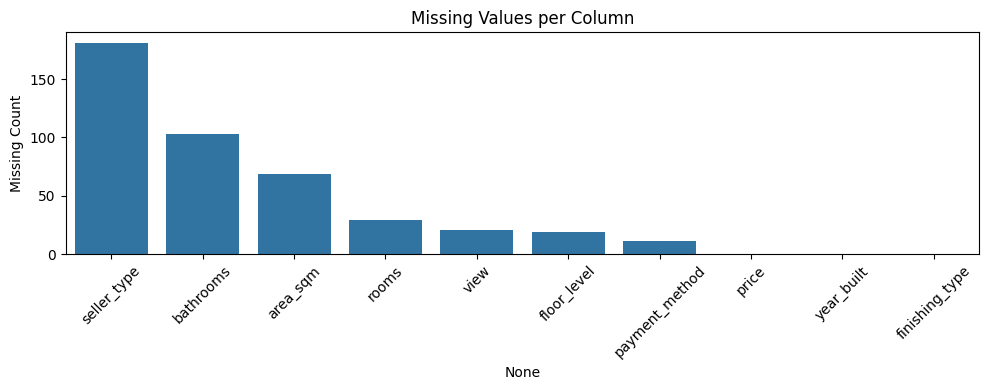

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_counts = df.isnull().sum().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
sns.barplot(x=missing_counts.index, y=missing_counts.values)
plt.title('Missing Values per Column')
plt.xticks(rotation=45)
plt.ylabel('Missing Count')
plt.tight_layout()
plt.show()

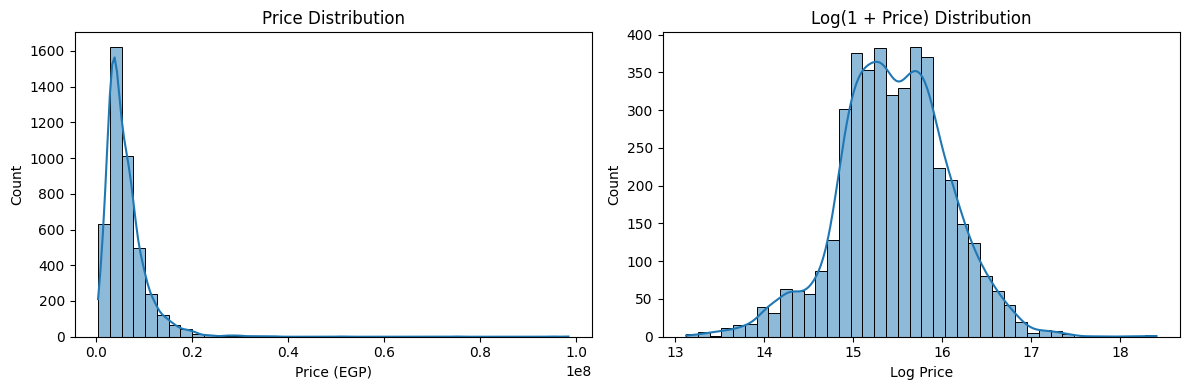

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price (EGP)')

sns.histplot(np.log1p(df['price']), bins=40, kde=True, ax=axes[1])
axes[1].set_title('Log(1 + Price) Distribution')
axes[1].set_xlabel('Log Price')

plt.tight_layout()
plt.show()

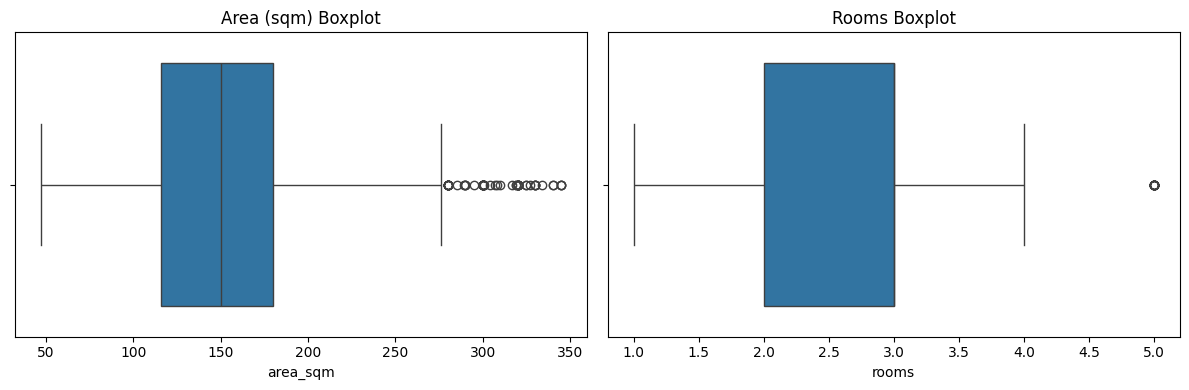

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['area_sqm'], ax=axes[0])
axes[0].set_title('Area (sqm) Boxplot')

sns.boxplot(x=df['rooms'], ax=axes[1])
axes[1].set_title('Rooms Boxplot')

plt.tight_layout()
plt.show()

In [8]:
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce')
df['area_sqm'] = pd.to_numeric(df['area_sqm'].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce')
df['rooms'] = pd.to_numeric(df['rooms'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
df['bathrooms'] = pd.to_numeric(df['bathrooms'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
df['floor_level'] = pd.to_numeric(df['floor_level'].replace({'Ground': '0'}), errors='coerce')
df['year_built'] = pd.to_numeric(df['year_built'], errors='coerce')

invalid_sellers = ['Cash', 'Cash or Installments', 'Installments']
df.loc[df['seller_type'].isin(invalid_sellers), 'seller_type'] = np.nan

df = df.dropna(subset=['price']).drop_duplicates()

for col in ['area_sqm', 'rooms', 'bathrooms', 'floor_level']:
    q_low = df[col].quantile(0.005)
    q_high = df[col].quantile(0.995)
    df.loc[(df[col] < q_low) | (df[col] > q_high), col] = np.nan

df = df.drop(columns=['price_per_sqm'])

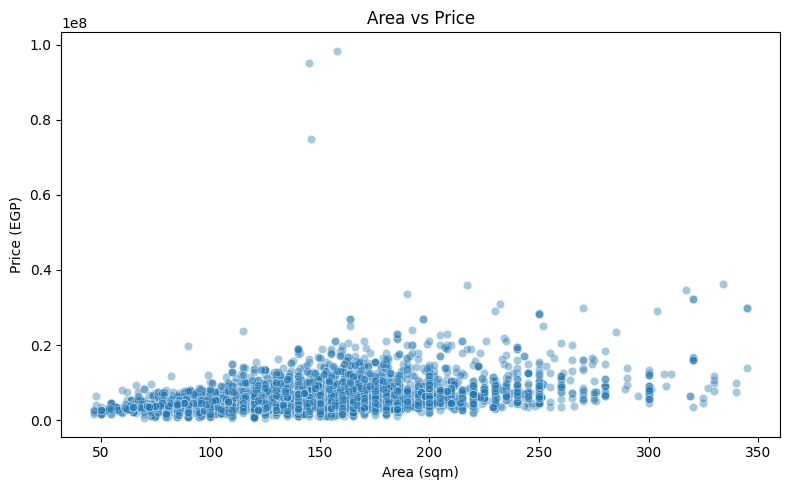

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='area_sqm', y='price', alpha=0.4)
plt.title('Area vs Price')
plt.xlabel('Area (sqm)')
plt.ylabel('Price (EGP)')
plt.tight_layout()
plt.show()

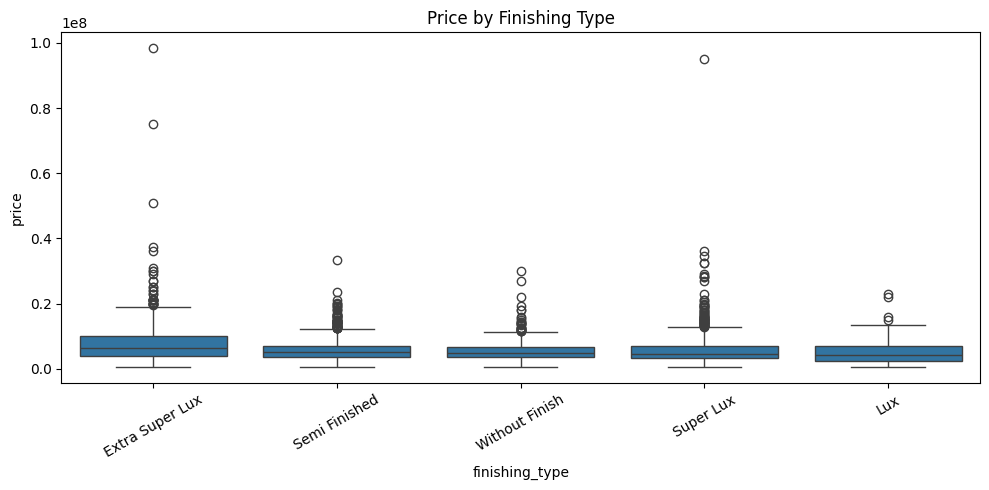

In [16]:
plt.figure(figsize=(10, 5))
order = df.groupby('finishing_type')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='finishing_type', y='price', order=order)
plt.title('Price by Finishing Type')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

df['rooms_per_100sqm'] = df['rooms'] / (df['area_sqm'] / 100.0)
df['building_age'] = 2026 - df['year_built']

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

In [19]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

models = {
    'Ridge': Ridge(alpha=10.0),
    'RandomForest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
}

results = []

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, preds),
        'RMSE': root_mean_squared_error(y_test, preds),
        'R2': r2_score(y_test, preds)
    })

comparison_df = pd.DataFrame(results).sort_values(by='RMSE')
print(comparison_df.to_string(index=False))

               Model          MAE         RMSE       R2
HistGradientBoosting 1.894410e+06 4.115002e+06 0.336138
        RandomForest 1.852579e+06 4.304978e+06 0.273427
               Ridge 2.366620e+06 4.393090e+06 0.243380
          ExtraTrees 1.953592e+06 4.600369e+06 0.170296


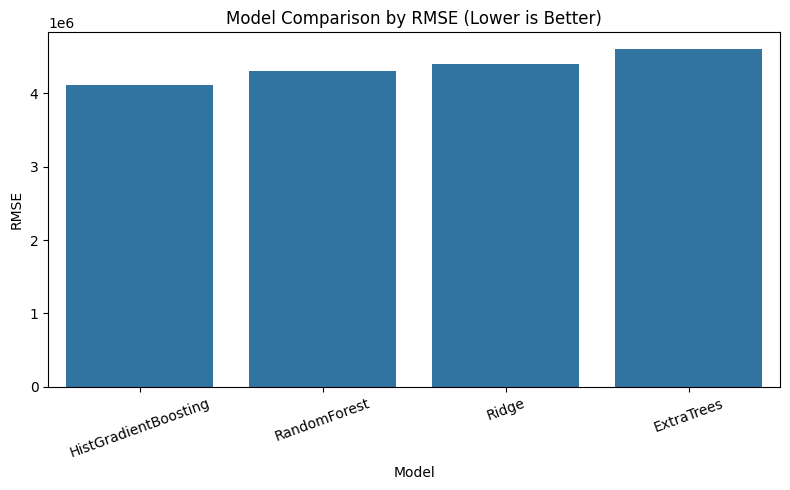

In [21]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x='Model', y='RMSE')
plt.title('Model Comparison by RMSE (Lower is Better)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score

best_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=31, random_state=42))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = -cross_val_score(best_model, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
print("5-Fold CV RMSE:", cv_scores.round(0))
print("Mean CV RMSE:", round(cv_scores.mean(), 0))

best_model.fit(X_train, y_train)
final_preds = best_model.predict(X_test)
print("Final Test MAE:", round(mean_absolute_error(y_test, final_preds), 0))
print("Final Test RMSE:", round(root_mean_squared_error(y_test, final_preds), 0))
print("Final Test R2:", round(r2_score(y_test, final_preds), 4))

5-Fold CV RMSE: [4044374. 3296322. 2716680. 4549221. 3011430.]
Mean CV RMSE: 3523605.0
Final Test MAE: 1785416.0
Final Test RMSE: 4044374.0
Final Test R2: 0.3587
